# V02: Customer Network Source and service gateway

Access an in-region OCI service without broadening its customer source-network restriction.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## When do you need an Advanced DNS entry?

Advanced DNS lets you specify hostnames whose traffic needs to use your customer VCN. Private hostnames can already use customer DNS through the workspace's private connection.

| Your destination | How it is handled | What you need to do |
| --- | --- | --- |
| A hostname resolvable from the AIDP service network, whose traffic must use your customer VCN—for example, an S3 or public OCI service endpoint | An explicit Advanced DNS entry configures handling through the customer-network connection. | Add the actual hostname used by your application. Verify the required customer routes, security rules, and service permissions. |
| A private hostname, such as a private ADB hostname, that the AIDP service resolver cannot resolve | DNS resolution uses the private-endpoint DNS proxy and customer DNS context by default. | Verify customer DNS, private connectivity, and destination access rules. An Advanced DNS entry is not required solely because the hostname is private. |

A private endpoint does not by itself determine whether an entry is needed. Use the actual connection hostname and its resolution behavior. Validate the connection with an authenticated application operation.

Regional service-zone allowances are a separate policy consideration; they are not another resolution path or proof of an automatically inserted workspace entry. DNS configuration does not create routes or grant service permissions. Keep using the hostname for TLS identity checks, even when AIDP returns a mapped address.

**Before testing:** record the complete DNS/SCAN list, endpoint type, existing overrides and effective client configuration. A successful query alone does not identify the resolution mechanism. Do not delete a shared override to create a clean baseline. Use an approved clean test workspace or mark the default-path claim **INCOMPLETE** when provenance cannot be established.

For V04, first test the private endpoint without adding a database Advanced DNS entry. Keep that database configuration fixed while adding, replacing and deleting unrelated service-resolvable test hostnames, repeating the database query in each phase and after restoration. For V01–V03, V06 and V07, explicit-entry tests require service-resolvable hostnames; private-only names are unsuitable for demonstrating that provisioning mechanism. An unresolved owned name can remain a deliberately negative V06 test.

The [public workspace guide](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html) lists broad private-network scenarios; endpoint type and deployed resolver behavior determine whether an explicit entry is necessary. The [ADB private endpoint guide](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html) describes the destination's private access setup. Confirm your deployment's behavior with the administrator and retain independent evidence for the resolution path you claim.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Workspace | Attach the private-network-enabled workspace to the VCN/subnet intended by the source restriction. |
| Route | Use an existing service gateway in that VCN and enable the supported regional service. Add/verify the regional service-CIDR route in the customer subnet route table and the applicable security rules. A more specific service route must take precedence over unrelated default egress. |
| DNS | Use the exact service endpoint your client calls. Configure advanced DNS for the destination when customer-VCN source context is required; verify the saved result and runtime resolution. |
| Security and identity | Use an identity already authorized by an unchanged IAM policy referencing your Network Source. Confirm the selected VCN and subnet ranges are in that source. Database network ACLs and OCI IAM Network Sources are different controls. |
| Evidence | Arrange access to policy/route records and correlated target request or network telemetry before testing. A successful read, translated destination IP, or public egress-IP check does not independently establish the service-gateway path. |


### Example network topology

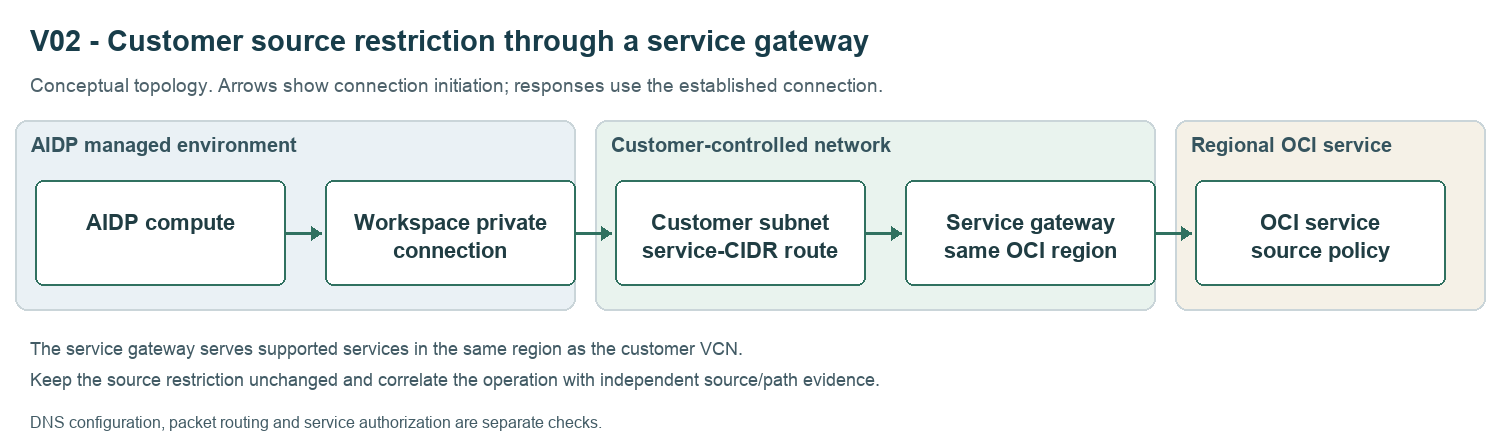

The diagram is illustrative; it does not prove the route taken by a request.


## IAM and network examples

Preparation templates only: replace every angle-bracket placeholder privately. An administrator prepares the approved resources; this notebook applies no policies or network changes.

### Separate operator, service and runtime permissions

The workspace operator needs access to the existing AIDP instance and the appropriate Workbench role/permissions to edit that workspace. Example OCI policies for an identity-domain group are:

```text
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to use ai-data-platforms in compartment <AIDP_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect vcns in compartment <VCN_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect subnets in compartment <SUBNET_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect network-security-groups in compartment <NSG_COMPARTMENT>
```

These statements allow instance access and network selection; they do not grant Workbench workspace-edit privileges, create infrastructure or authorize reads from data sources. Use the existing approved Workbench role. Policies belong in the relevant compartment or an ancestor with authority over that scope.

The platform also needs its private-network service permissions. The following adapts the documented AIDP network statements to explicit resource compartments and one instance:

```text
Allow any-user to manage vnics in compartment <VNIC_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use subnets in compartment <SUBNET_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use network-security-groups in compartment <NSG_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
```

Select the actual instance principal type (`aidataplatform` or the applicable legacy type), instance ID and placement compartments with your administrator. Retain the other existing service setup policies; this is not a full tenancy bootstrap. The runtime reading data can use a different identity from the operator or AIDP service: establish the connector's effective signer before choosing its policy subject.

Sources: [AIDP IAM policies](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/iam-policies-oracle-ai-data-platform.html), [AIDP workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html), [IAM policy scope](https://docs.oracle.com/en-us/iaas/Content/Security/Reference/iam_security_topic-IAM_Security_Policies.htm).

### Platform network baseline

The current workspace guide requires ingress from the customer VCN address range to all destination ports for private-network data access. An example baseline rule is **ingress; source CIDR `<CUSTOMER_VCN_CIDR>`; all protocols/ports; stateful**, in the security control selected for that workspace topology. Have the administrator reconcile this platform prerequisite with the approved design. The target-specific examples below are additional destination controls, not a replacement for platform rules. Do not use an internet-wide ingress rule.

Retain working DNS resolver access. With custom resolvers, permit UDP and TCP 53 to the approved resolver and configure forwarding/resolution in the customer network. Explicit Advanced DNS provisioning requires service-side resolvability; a successful customer-only lookup does not establish that prerequisite. Private ADB names unresolved by the service resolver use the default private DNS proxy/customer resolver path. Do not add them solely because they are private. Advanced DNS does not create a customer DNS zone, resolver endpoint, route, NAT gateway, service gateway or database listener. Use stateful connection rules in these examples; stateless designs need explicit return rules. Security lists and NSGs are additive, so check all applicable rules.

Source: [OCI security rules](https://docs.oracle.com/en-us/iaas/Content/Network/Concepts/securityrules.htm).

### Runtime policy with source restriction

For a connector authenticated as a user in the named group, a fixture read can use:

```text
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

For a connector using a verified resource-principal dynamic group, use that subject instead, for example:

```text
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

Choose the subject matching the actual signer; do not grant both variants by default. An existing dynamic group must match that resource; these samples do not define a generic AIDP matching rule. Reading objects includes listing objects in the named bucket. No object write privilege is needed. If the chosen connector separately resolves the namespace, verify its namespace-read permission under its existing setup.

Create the Network Source in the tenancy home region with a **VCN entry** containing `<CUSTOMER_VCN_ID>` and `<WORKSPACE_SUBNET_CIDR>`. This is the allowed source network, not the translated destination address from a DNS answer. Keep the restriction unchanged during the comparison. OCI policies are additive: another unconditional allow for the same operation can invalidate this test; review effective grants before claiming a source restriction was enforced. Do not apply this example to the tenancy's console sign-in restriction.

### Route and security example

| Control | Example |
| --- | --- |
| Service gateway | Enable the supported Object Storage service label for `<WORKSPACE_REGION>`. |
| Subnet route | Destination type **Service**, destination the regional Object Storage service CIDR label, target `<SERVICE_GATEWAY_ID>`. |
| Egress | Destination type **Service**, same regional service label, stateful TCP 443. Preserve platform baseline rules. |
| Advanced DNS | Exact in-region service FQDN selected for customer source context. |

The service gateway serves supported services in its own region. Keep the policy, route and signer fixed; correlate the successful read with the intended source/path. A database ACL is a separate control.

Sources: [Network Sources](https://docs.oracle.com/en-us/iaas/Content/Identity/Tasks/managingnetworksources.htm), [service gateways](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm), [Object Storage policy examples](https://docs.oracle.com/en/solutions/oci-object-storage-modernization/configure-tenancy.html).


## Test procedure

1. Capture the existing restriction, intended source network, route and identity label.
2. Read the known small in-region Object Storage CSV before and after the scoped FQDN change, keeping identity and client unchanged.
3. Correlate the operation with source/network evidence while the restriction remains unchanged.
4. Restore the saved DNS baseline and repeat the original control.

**Acceptance:** The fixture read passes under the unchanged restriction AND reviewed independent evidence establishes the intended customer source/path. Keep an ADB ACL variant separately labeled.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V02': 'Customer Network Source and service gateway'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def fixture_read(spark, cfg):
    """Bounded CSV check; connector options apply to this reader, not globally."""
    for key in ('uri', 'endpoint', 'expected_rows'):
        if not cfg.get(key):
            raise Prerequisite('Missing fixture ' + key)
    uri, endpoint = (cfg['uri'], cfg['endpoint'])
    if '?' in uri or '#' in uri or '?' in endpoint or ('#' in endpoint):
        raise Prerequisite('Use unsigned fixture and endpoint references')
    parsed_endpoint = urlsplit(endpoint if '://' in endpoint else 'https://' + endpoint)
    if parsed_endpoint.username is not None or parsed_endpoint.password is not None:
        raise Prerequisite('Endpoint must not contain embedded credentials')
    if not parsed_endpoint.hostname:
        raise Prerequisite('Missing endpoint hostname')
    if uri.startswith('s3a://') and '@' in uri.split('://', 1)[1].split('/', 1)[0]:
        raise Prerequisite('S3 URI must not contain embedded credentials')
    expected = cfg['expected_rows']
    if not isinstance(expected, list) or not 1 <= len(expected) <= 100:
        raise Prerequisite('Supply 1 to 100 expected synthetic CSV rows')
    size = cfg.get('fixture_size_bytes')
    if not isinstance(size, int) or isinstance(size, bool) or (not 0 < size <= 65536):
        raise Prerequisite('Verify fixture size is between 1 byte and 64 KiB')
    reader = spark.read.option('header', 'true').option('inferSchema', 'false')
    if uri.startswith('s3a://'):
        if not cfg.get('region'):
            raise Prerequisite('Missing AWS region')
        reader = reader.option('fs.s3a.endpoint', endpoint).option('fs.s3a.endpoint.region', cfg['region'])
    elif uri.startswith('oci://'):
        authority = uri.split('://', 1)[1].split('/', 1)[0]
        if authority.count('@') != 1:
            raise Prerequisite('OCI URI must specify bucket@namespace')
        bucket, namespace = authority.split('@')
        reader = reader.option('fs.oci.client.hostname.' + bucket + '.' + namespace, endpoint)
    else:
        raise Prerequisite('Use s3a:// or oci://')
    rows = reader.csv(uri).limit(len(expected) + 1).collect()
    actual = [r.asDict() for r in rows]
    assert collections.Counter(map(canonical, actual)) == collections.Counter(map(canonical, expected)), 'Fixture content mismatch'
    return {'rows': len(actual), 'fixture_assertion': 'exact row multiset', 'configured_endpoint': endpoint}

def adb_read(spark, cfg, runtime):
    """Use an existing catalog connection or an existing wallet ZIP.

    runtime carries secrets in memory only and is never included in results.
    No wallet is generated/copied; provide a supported existing ZIP or catalog.
    """
    if not cfg.get('expected_instance'):
        raise Prerequisite('Missing expected database identity')
    reader = spark.read.format('aidataplatform').option('type', 'ORACLE_ALH').option('schema', 'SYS').option('table', 'DUAL').option('pushdown.sql', "SELECT sys_context('userenv','instance_name') AS INSTANCE_NAME FROM dual").option('login.timeout.seconds', '20')
    if cfg.get('catalog_id'):
        reader = reader.option('catalog.id', cfg['catalog_id'])
    else:
        if not cfg.get('wallet_zip') or not cfg.get('tns') or (not cfg.get('user')):
            raise Prerequisite('Existing catalog or wallet ZIP/TNS/user required')
        password = runtime.get('adb_password')
        if not password:
            raise Prerequisite('ADB password is missing from runtime context')
        reader = reader.option('wallet.path', cfg['wallet_zip']).option('tns', cfg['tns']).option('user.name', cfg['user']).option('password', password)
    rows = reader.load().limit(2).collect()
    assert len(rows) == 1, 'Identity query must return one row'
    assert str(rows[0][0]) == cfg['expected_instance'], 'Unexpected database identity'
    return {'rows': 1, 'identity_matches': True, 'transport_claim': 'Authenticated query; mTLS not independently established'}

def run_case(case, cfg, spark=None, runtime=None, live=False, phase='baseline'):
    if case not in CASE_NAMES:
        raise ValueError('Unknown case')
    result = {'case': case, 'name': CASE_NAMES[case], 'utc': utc(), 'phase': phase, 'workspace_label': cfg.get('workspace_label'), 'compute_label': cfg.get('compute_label'), 'checks': {}, 'origin': 'harness'}
    checks = result['checks']

    def check(name, action):
        started = time.monotonic()
        try:
            checks[name] = {'status': 'PASS', 'detail': action()}
        except Prerequisite as exc:
            checks[name] = {'status': 'BLOCKED', 'reason': str(exc)}
        except Exception as exc:
            checks[name] = {'status': 'FAIL', 'error_type': type(exc).__name__}
        checks[name]['elapsed_seconds'] = round(time.monotonic() - started, 3)
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    if spark is None:
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Existing Spark session required'}
        return result
    if not cfg.get('workspace_label') or not cfg.get('compute_label'):
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Record workspace and compute labels'}
        return result

    def spark_control():
        value = spark.sql('SELECT 1').collect()[0][0]
        assert value == 1, 'Spark control query returned unexpected result'
        return {'select_1': value, 'application_id': spark.sparkContext.applicationId}
    check('spark_control', spark_control)
    host = cfg.get('hostname') or endpoint_host(cfg.get('endpoint', ''))
    if not host:
        checks['dns'] = {'status': 'BLOCKED', 'reason': 'Missing exact hostname'}
    else:
        check('dns', lambda: {'addresses': sorted({a[4][0] for a in socket.getaddrinfo(host, cfg.get('port', 443), type=socket.SOCK_STREAM)})})
        if cfg.get('probe_tcp', False):

            def tcp():
                with socket.create_connection((host, cfg.get('port', 443)), timeout=5):
                    return {'connected': True, 'tls_verified': False}
            check('tcp', tcp)
        else:
            checks['tcp'] = {'status': 'NOT_RUN'}
    if cfg.get('kind') == 'csv':
        check('functional', lambda: fixture_read(spark, cfg))
    elif cfg.get('kind') == 'adb':
        check('functional', lambda: adb_read(spark, cfg, runtime or {}))
        checks['mtls'] = {'status': 'BLOCKED', 'reason': 'Requires separate effective-descriptor and client-certificate evidence'}
    else:
        checks['functional'] = {'status': 'BLOCKED', 'reason': 'Configure kind=csv or adb'}
    checks['source_path'] = {'status': 'BLOCKED', 'reason': 'Independent path evidence required; successful read is insufficient'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V02'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443,
 'kind': 'csv',
 'uri': '',
 'endpoint': '',
 'region': '',
 'workspace_region': '',
 'fixture_size_bytes': 0,
 'expected_rows': [{'id': '1', 'label': 'alpha'}, {'id': '2', 'label': 'beta'}]}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


## Run a workload phase

Use the same identity and client before and after a supported change. Only set RUN_LIVE=True when prerequisites are ready. For subsequent phases, change PHASE and rerun this cell without reinitializing RESULTS. The runtime password hook reads an already-provisioned environment variable; it never prints its value. The sample does not configure the S3A credential provider or install connector libraries.


In [ ]:
import os
RUNTIME = {}
if os.environ.get("ADB_PASSWORD"):
    RUNTIME["adb_password"] = os.environ["ADB_PASSWORD"]
result = run_case(CASE_ID, CONFIG, spark=globals().get("spark"), runtime=RUNTIME, live=RUN_LIVE, phase=PHASE)
result["acceptance"] = summarize(result)
RESULTS.append(result)
print(json.dumps(result, indent=2))


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None}


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)
- [sgw](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm)
- [sources](https://docs.oracle.com/en-us/iaas/Content/Identity/Tasks/managingnetworksources.htm)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
